Hands found in 147764/159398 images (92.7%)
Hands found in 127441/137798 images (92.5%)
['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y']


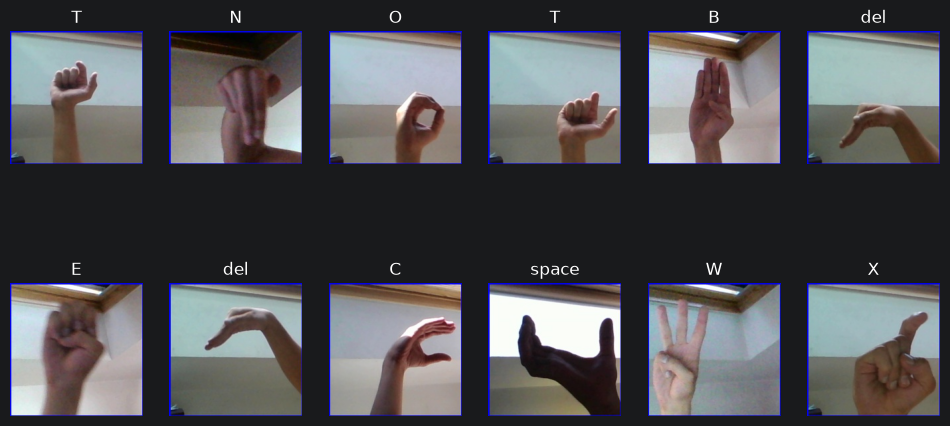

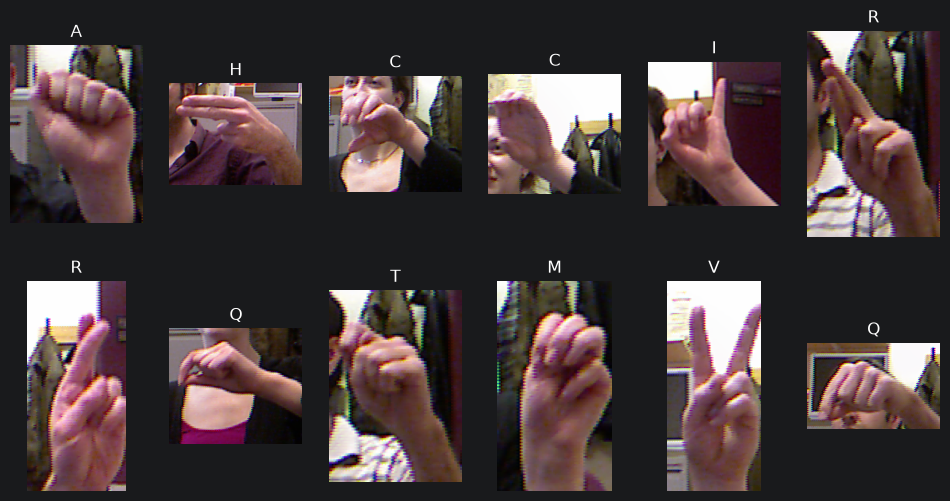

In [32]:
import torch
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Dataset, Subset
from torchvision import datasets, transforms

from hand_crop import HandCropDataset, compute_boxes

DATA_DIR = Path("..") / "data"
TRAIN_DIR = DATA_DIR / "asl_alphabet_train" / "asl_alphabet_train"
TEST_DIR = DATA_DIR / "asl_alphabet_test" / "asl_alphabet_test"
TEST_DIR_DIFF = DATA_DIR / "pugeault" / "dataset5"
HAND_BOXES_CACHE = DATA_DIR / "hand_boxes.json"
EXTRA_TRAIN_DIR = DATA_DIR / "Train_Alphabet"


def build_transforms(img_size=224, mean=(0.5,) * 3, std=(0.5,) * 3, augment=None):
    base = [transforms.Resize((img_size, img_size))]
    post = [transforms.ToTensor(), transforms.Normalize(mean, std)]
    if augment is None:
        augment = [
            transforms.RandomRotation(10),
            transforms.ColorJitter(brightness=0.2, contrast=0.2),
            transforms.RandomHorizontalFlip(p=0.5),
        ]
    train_tf = transforms.Compose(base + list(augment) + post)
    eval_tf = transforms.Compose(base + post)
    return train_tf, eval_tf


class PugeaultDataset(Dataset):
    def __init__(self, root, class_to_idx, persons=("A", "B", "C", "D", "E")):
        self.files, self.targets = [], []
        for person in persons:
            for letter_dir in sorted((Path(root) / person).iterdir()):
                if not letter_dir.is_dir():
                    continue
                label = class_to_idx[letter_dir.name.upper()]
                for p in sorted(letter_dir.glob("*.png")):
                    self.files.append(p)
                    self.targets.append(label)

    def __len__(self):
        return len(self.files)

    def __getitem__(self, i):
        return Image.open(self.files[i]).convert("RGB"), self.targets[i]


class ASLTestDataset(Dataset):
    def __init__(self, root, class_to_idx):
        self.files = sorted(Path(root).glob("*.jpg"))
        self.targets = [class_to_idx[p.stem.split("_")[0]] for p in self.files]

    def __len__(self):
        return len(self.files)

    def __getitem__(self, i):
        return Image.open(self.files[i]).convert("RGB"), self.targets[i]


class FileListDataset(Dataset):
    def __init__(self, samples, classes, class_to_idx):
        self.files = [Path(p) for p, _ in samples]
        self.targets = [y for _, y in samples]
        self.classes, self.class_to_idx = classes, class_to_idx

    def __len__(self):
        return len(self.files)

    def __getitem__(self, i):
        return Image.open(self.files[i]).convert("RGB"), self.targets[i]


def get_targets(ds):
    if isinstance(ds, Subset):
        base = get_targets(ds.dataset)
        return [base[i] for i in ds.indices]
    return list(ds.targets)


class FilteredDataset(Dataset):
    def __init__(self, ds, keep, class_to_idx):
        self.ds = ds
        self.classes = list(keep)
        old_to_new = {class_to_idx[c]: i for i, c in enumerate(keep)}
        pairs = [(i, old_to_new[y]) for i, y in enumerate(get_targets(ds)) if y in old_to_new]
        self.indices = [i for i, _ in pairs]
        self.targets = [y for _, y in pairs]

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, i):
        img, _ = self.ds[self.indices[i]]
        return img, self.targets[i]


def get_paths(ds):
    if isinstance(ds, Subset):
        base = get_paths(ds.dataset)
        return [base[i] for i in ds.indices]
    if isinstance(ds, FilteredDataset):
        base = get_paths(ds.ds)
        return [base[i] for i in ds.indices]
    if isinstance(ds, datasets.ImageFolder):
        return [p for p, _ in ds.samples]
    return list(ds.files)


class TransformedDataset(Dataset):
    def __init__(self, ds, transform):
        self.ds = ds
        self.transform = transform
        self.classes = getattr(ds, "classes", None)
        self.targets = getattr(ds, "targets", None)

    def __len__(self):
        return len(self.ds)

    def __getitem__(self, i):
        img, y = self.ds[i]
        return self.transform(img), y


def default_keep_classes(classes):
    return [c for c in classes if len(c) == 1 and c not in ("J", "Z")]


def build_datasets(train_tf, eval_tf, valid_size=0.2, seed=42, keep_classes=None, augmentation=True, extraData=True,
                   crop_hands=True, crop_margin=0.25, drop_missing=False):
    base = datasets.ImageFolder(TRAIN_DIR)
    samples = list(base.samples)
    if extraData:
        extra = datasets.ImageFolder(EXTRA_TRAIN_DIR)
        samples += [(p, base.class_to_idx[extra.classes[y]])
                    for p, y in extra.samples
                    if extra.classes[y] in base.class_to_idx]
    raw = FileListDataset(samples, base.classes, base.class_to_idx)
    if keep_classes is None:
        keep_classes = default_keep_classes(raw.classes)

    tr_idx, va_idx = train_test_split(
        list(range(len(raw))), test_size=valid_size, random_state=seed, stratify=raw.targets
    )

    splits = {
        "train": (Subset(raw, tr_idx), train_tf if augmentation==True else eval_tf),
        "valid": (Subset(raw, va_idx), eval_tf),
        "test": (ASLTestDataset(TEST_DIR, raw.class_to_idx), eval_tf),
        "test_pug": (PugeaultDataset(TEST_DIR_DIFF, raw.class_to_idx), eval_tf),
    }
    filtered = {name: FilteredDataset(ds, keep_classes, raw.class_to_idx) for name, (ds, _) in splits.items()}

    if crop_hands:
        paths = {name: get_paths(ds) for name, ds in filtered.items()}
        boxes = compute_boxes([p for ps in paths.values() for p in ps], HAND_BOXES_CACHE)
        filtered = {
            name: HandCropDataset(ds, paths[name], boxes, margin=crop_margin, drop_missing=drop_missing)
            for name, ds in filtered.items()
        }

    out = {name: TransformedDataset(ds, splits[name][1]) for name, ds in filtered.items()}
    return out, keep_classes


def build_loaders(train_tf, eval_tf, batch_size=128, valid_size=0.2,
                seed=42, keep_classes=None,augmentation=True, extraData=True, **crop_kwargs):
    ds, keep_classes = build_datasets(train_tf, eval_tf, valid_size, seed, keep_classes, augmentation, extraData, **crop_kwargs)
    loaders = {
        name: DataLoader(d, batch_size=batch_size, shuffle=(name == "train"))
        for name, d in ds.items()
    }
    return loaders, keep_classes


train_tf, eval_tf = build_transforms(img_size=200)
loaders, classes = build_loaders(train_tf, eval_tf, batch_size=128, crop_hands=True, crop_margin=0.25)
loaders_base, classes_base = build_loaders(train_tf, eval_tf, batch_size=128, augmentation=False, extraData=False, crop_hands=False, crop_margin=0.25)
loaders_aug, classes_aug = build_loaders(train_tf, eval_tf, batch_size=128, extraData=False, crop_hands=False, crop_margin=0.25)
loaders_crop, classes_crop = build_loaders(train_tf, eval_tf, batch_size=128, augmentation=False, extraData=False, crop_hands=True, crop_margin=0.25)
loaders_extended, classes_extended = build_loaders(train_tf, eval_tf, batch_size=128, augmentation=False, crop_hands=False, crop_margin=0.25)

train_loader, valid_loader, test_loader, test_pug_loader = loaders["train"], loaders["valid"], loaders["test"], loaders["test_pug"]

train_loader_base, valid_loader_base, test_loader_base, test_pug_loader_base = loaders_base["train"], loaders_base["valid"], loaders_base["test"], loaders_base["test_pug"]

train_loader_aug, valid_loader_aug, test_loader_aug, test_pug_loader_aug = loaders_aug["train"], loaders_aug["valid"], loaders_aug["test"], loaders_aug["test_pug"]

train_loader_crop, valid_loader_crop, test_loader_crop, test_pug_loader_crop = loaders_crop["train"], loaders_crop["valid"], loaders_crop["test"], loaders_crop["test_pug"]

train_loader_extended, valid_loader_extended, test_loader_extended, test_pug_loader_extended = loaders_extended["train"], loaders_extended["valid"], loaders_extended["test"], loaders_extended["test_pug"]

print(classes)

raw = datasets.ImageFolder(TRAIN_DIR)
fig, axes = plt.subplots(2, 6, figsize=(12, 6))
for ax, idx in zip(axes.flat, torch.randint(len(raw), (12,)).tolist()):
    img, label = raw[idx]
    ax.imshow(img); ax.set_title(raw.classes[label]); ax.axis("off")
plt.show()




raw_pug = PugeaultDataset(TEST_DIR_DIFF, raw.class_to_idx)
fig, axes = plt.subplots(2, 6, figsize=(12, 6))
for ax, idx in zip(axes.flat, torch.randint(len(raw_pug), (12,)).tolist()):
    img, label = raw_pug[idx]
    ax.imshow(img); ax.set_title(raw.classes[label]); ax.axis("off")
plt.show()


In [33]:
from collections import Counter


def source_paths(ds):
    if isinstance(ds, TransformedDataset):
        return source_paths(ds.ds)
    if isinstance(ds, HandCropDataset):
        base = source_paths(ds.ds)
        return [base[i] for i in ds.indices]
    return get_paths(ds)


def source_counts(loaders_dict, splits=("train", "valid")):
    for split in splits:
        paths = source_paths(loaders_dict[split].dataset)
        c = Counter("Train_Alphabet" if EXTRA_TRAIN_DIR.name in p.parts else "asl_alphabet_train"
                    for p in map(Path, paths))
        print(f"{split:6s} total={len(paths):6d}  " + "  ".join(f"{k}={v}" for k, v in c.items()))


print("extended:"); source_counts(loaders_extended)
print("combined:"); source_counts(loaders)
print("baseline:"); source_counts(loaders_base)

print("\nadded by extra data (extended - baseline):")
for split in ("train", "valid"):
    print(split, len(loaders_extended[split].dataset) - len(loaders_base[split].dataset))


extended:
train  total= 74880  Train_Alphabet=17278  asl_alphabet_train=57602
valid  total= 18720  Train_Alphabet=4322  asl_alphabet_train=14398
combined:
train  total= 74880  Train_Alphabet=17278  asl_alphabet_train=57602
valid  total= 18720  Train_Alphabet=4322  asl_alphabet_train=14398
baseline:
train  total= 57600  asl_alphabet_train=57600
valid  total= 14400  asl_alphabet_train=14400

added by extra data (extended - baseline):
train 17280
valid 4320


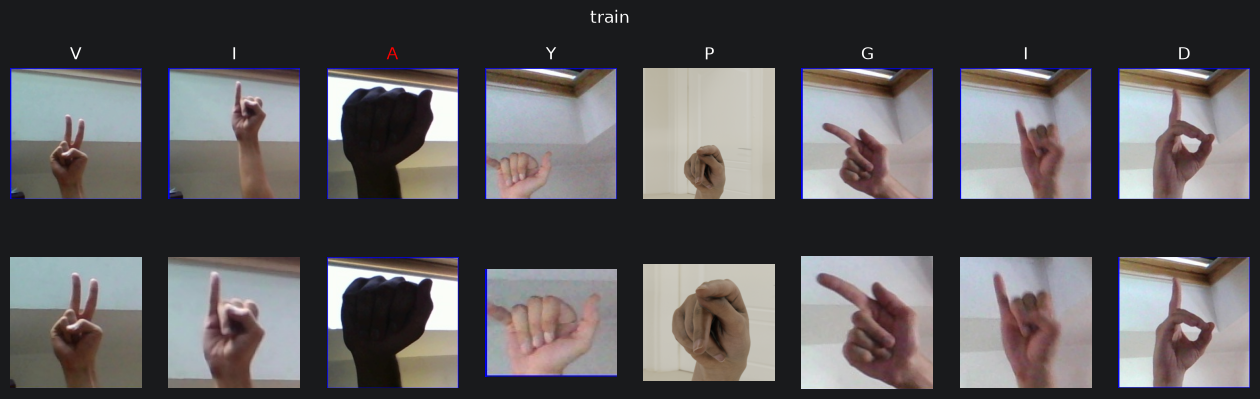

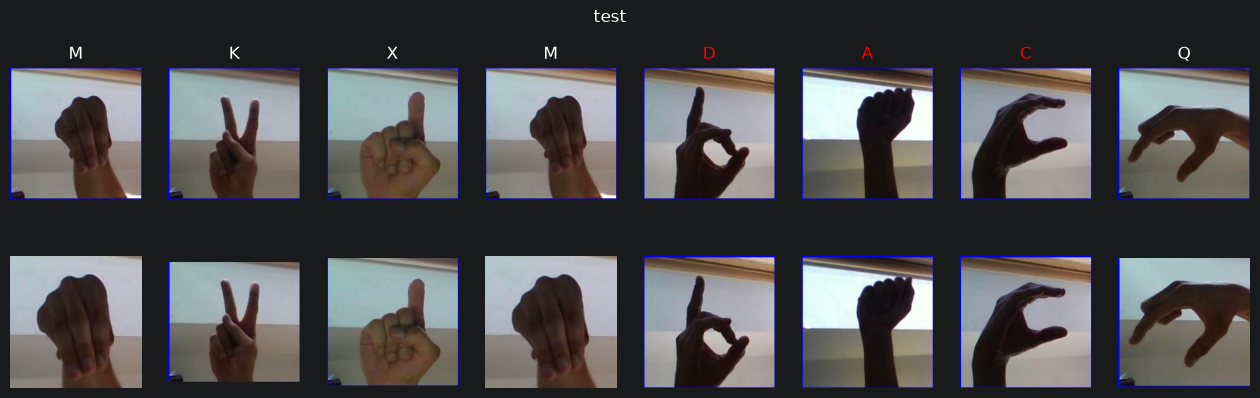

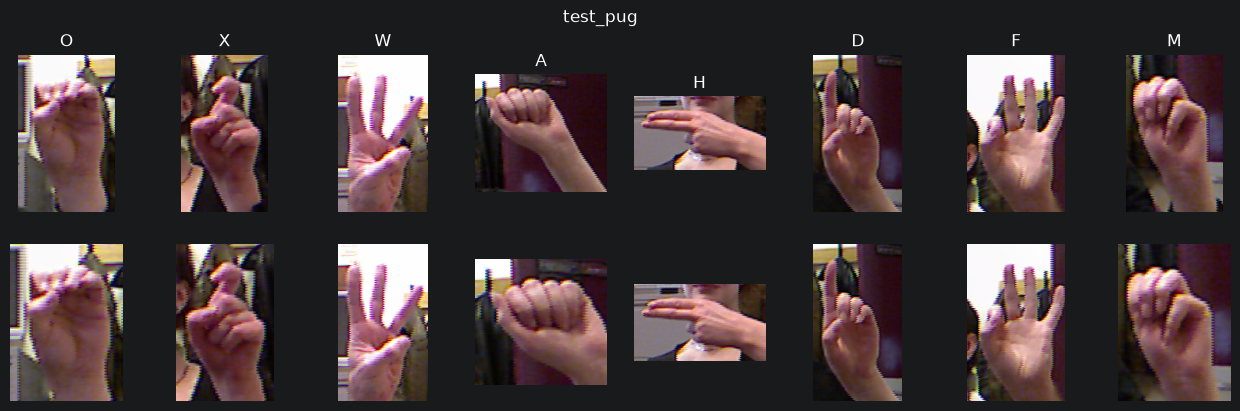

In [34]:
from hand_crop import crop_hand


def show_crops(name, n=8):
    ds = loaders[name].dataset.ds
    idxs = torch.randint(len(ds), (n,)).tolist()
    fig, axes = plt.subplots(2, n, figsize=(2 * n, 4.5))
    for j, i in enumerate(idxs):
        orig, y = ds.ds[ds.indices[i]]
        box = ds.boxes[i]
        axes[0, j].imshow(orig)
        axes[0, j].set_title(classes[y], color="white" if box else "red")
        axes[1, j].imshow(crop_hand(orig, box, ds.margin))
    for ax in axes.flat:
        ax.axis("off")
    fig.suptitle(name)
    plt.show()


for name in ("train", "test", "test_pug"):
    show_crops(name)


## Grad-CAM analysis

Grad-CAM shows which regions of the input drove a prediction: the gradients of the class score w.r.t. a conv layer's feature maps weight those maps, and their ReLU'd sum is upsampled to a heatmap (see `grad_cam.py`).

The cells below expect a trained CNN in `model` (any architecture with a `nn.Conv2d`; the last one is used by default — set `target_layer` to inspect another). To compare training pipelines, put several trained models in `models` as `{name: (model, loaders_dict)}`, e.g. `{"base": (model_base, loaders_base), "crop": (model_crop, loaders_crop)}`.

1. **Examples** – heatmaps on random and misclassified test images.
2. **Confusions** – one image explained w.r.t. two letters it could be confused with.
3. **Per-class mean maps** – exposes dataset bias (e.g. attention on a constant background area).
4. **Hand energy** – share of Grad-CAM mass inside the MediaPipe hand box vs. the box's area (ratio > 1 ⇒ the model focuses on the hand).

In [ ]:
import json
from grad_cam import (GradCAM, find_last_conv, show_gradcam, show_compare_classes,
                      show_class_cams, hand_energy, summarize_energy)

assert "model" in globals(), "train a model first and assign it to `model`"
model.eval()
target_layer = find_last_conv(model)
print("Grad-CAM target layer:", target_layer)

show_gradcam(model, target_layer, test_loader, classes, n=8, title="ASL test set")
show_gradcam(model, target_layer, test_pug_loader, classes, n=8, title="Pugeault test set (random sample)")
show_gradcam(model, target_layer, test_pug_loader, classes, n=8, only="wrong", title="Pugeault – misclassified")

In [ ]:
# Explain one image w.r.t. visually similar letters (edit the pair to taste)
image, label = test_loader.dataset[0]
show_compare_classes(model, target_layer, image, classes, [classes[label], "S", "E"])

In [ ]:
show_class_cams(model, target_layer, valid_loader, classes, max_batches=20, title="Validation – mean Grad-CAM per class")
show_class_cams(model, target_layer, test_pug_loader, classes, max_batches=20, title="Pugeault – mean Grad-CAM per class")

In [ ]:
# Does the model look at the hand? Uses the cached MediaPipe boxes.
# Loaders must not shuffle, so the train split is skipped.
boxes = json.loads(HAND_BOXES_CACHE.read_text())
models = globals().get("models") or {"model": (model, loaders)}

results = {}
for name, (m, lds) in models.items():
    layer = find_last_conv(m)
    for split in ("valid", "test", "test_pug"):
        results[f"{name}/{split}"] = hand_energy(m, layer, lds[split], boxes, max_batches=10)
summarize_energy(results)